In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
!pip install -q transformers datasets

import torch
print(f'PyTorch : {torch.__version__}')
print(f'CUDA    : {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU     : {torch.cuda.get_device_name(0)}')
    print(f'VRAM    : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')

PyTorch : 2.10.0+cu128
CUDA    : True
GPU     : Tesla T4
VRAM    : 15.6 GB


In [3]:
from datasets import load_dataset

print("Downloading Cityscapes...")
ds = load_dataset("Chris1/cityscapes")
print(f"Train : {len(ds['train'])} images")
print(f"Val   : {len(ds['validation'])} images")
print("Done.")

dataset_infos.json:   0%|          | 0.00/864 [00:00<?, ?B/s]

data/train-00000-of-00014.parquet:   0%|          | 0.00/487M [00:00<?, ?B/s]

data/train-00001-of-00014.parquet:   0%|          | 0.00/521M [00:00<?, ?B/s]

data/train-00002-of-00014.parquet:   0%|          | 0.00/503M [00:00<?, ?B/s]

data/train-00003-of-00014.parquet:   0%|          | 0.00/494M [00:00<?, ?B/s]

...

data/test-00006-of-00007.parquet:   0%|          | 0.00/495M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/2975 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/500 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1525 [00:00<?, ? examples/s]

Train : 2975 images
Val   : 500 images
Done.


In [4]:
import numpy as np

# Official Cityscapes labelId → trainId mapping
# Any labelId not in this map gets 255 (ignore)
LABEL_TO_TRAIN = {
    0: 255, 1: 255, 2: 255, 3: 255, 4: 255, 5: 255,
    6: 255, 7: 0,   8: 1,   9: 255, 10: 255, 11: 2,
    12: 3,  13: 4,  14: 255, 15: 255, 16: 255, 17: 5,
    18: 255, 19: 6,  20: 7,   21: 8,   22: 9,   23: 10,
    24: 11,  25: 12, 26: 13,  27: 14,  28: 15,  29: 255,
    30: 255, 31: 16, 32: 17,  33: 18,
}

def convert_mask(mask_rgb):
    """
    Input : (H, W, 3) RGB mask from HuggingFace dataset
    Output: (H, W)    uint8 mask with trainId values (0-18, 255)
    
    The HF mask stores labelId in the R channel (all 3 channels are identical).
    """
    label_mask = np.array(mask_rgb)[:, :, 0]  # take R channel = labelId
    train_mask = np.full_like(label_mask, 255, dtype=np.uint8)
    for label_id, train_id in LABEL_TO_TRAIN.items():
        train_mask[label_mask == label_id] = train_id
    return train_mask

# Test on one sample
sample     = ds['train'][0]
raw_mask   = np.array(sample['semantic_segmentation'])
converted  = convert_mask(raw_mask)

print(f"Raw mask shape    : {raw_mask.shape}")
print(f"Converted shape   : {converted.shape}")
print(f"Converted unique  : {np.unique(converted)}")
print(f"Expected          : values 0-18 and 255 only")

ok = all(v in list(range(19)) + [255] for v in np.unique(converted))
print(f"Conversion OK     : {ok}")

Raw mask shape    : (1024, 2048, 3)
Converted shape   : (1024, 2048)
Converted unique  : [  0   1   2   5   7   8   9  10  11  12  13  18 255]
Expected          : values 0-18 and 255 only
Conversion OK     : True


In [5]:
import os

# Model — B2 this time
MODEL_VARIANT      = 'b2'
BATCH_SIZE         = 4       # P100/T4 can handle 4 with B2
ACCUMULATION_STEPS = 2
EPOCHS             = 50
FREEZE_EPOCHS      = 15
WARMUP_EPOCHS      = 5
CROP_SIZE          = 512
LR                 = 0.0001
LR_ENCODER         = 0.00001
WEIGHT_DECAY       = 0.01
FP16               = True
PATIENCE           = 15
NUM_WORKERS        = 2
MAX_TRAIN          = None    # full 2975
MAX_VAL            = None    # full 500
SAVE_VIZ_EVERY     = 5
RUN_NAME           = 'segformer-b2-full-cityscapes'

# Kaggle output dir
OUTPUT_DIR = f'/kaggle/working/{RUN_NAME}'
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f'Model     : SegFormer-{MODEL_VARIANT.upper()}')
print(f'Batch     : {BATCH_SIZE} x accum={ACCUMULATION_STEPS} = effective {BATCH_SIZE*ACCUMULATION_STEPS}')
print(f'Epochs    : {EPOCHS}  freeze={FREEZE_EPOCHS}  warmup={WARMUP_EPOCHS}')
print(f'Train     : full 2975')
print(f'Output    : {OUTPUT_DIR}')

Model     : SegFormer-B2
Batch     : 4 x accum=2 = effective 8
Epochs    : 50  freeze=15  warmup=5
Train     : full 2975
Output    : /kaggle/working/segformer-b2-full-cityscapes


In [6]:
import torch
import random
import numpy as np
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF
import torchvision.transforms as T
from PIL import Image

class HFCityscapesDataset(Dataset):
    MEAN = [0.485, 0.456, 0.406]
    STD  = [0.229, 0.224, 0.225]

    def __init__(self, hf_split, crop_size=512, split='train', max_samples=None):
        self.data      = hf_split
        self.crop_size = crop_size
        self.split     = split
        if max_samples and max_samples < len(self.data):
            self.data = self.data.select(range(max_samples))
        print(f'  [{split:5s}] {len(self.data)} samples')

    def convert_mask(self, mask_rgb):
        label = np.array(mask_rgb)[:, :, 0]
        train = np.full_like(label, 255, dtype=np.uint8)
        for lid, tid in LABEL_TO_TRAIN.items():
            train[label == lid] = tid
        return Image.fromarray(train)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        sample = self.data[idx]
        image  = sample['image'].convert('RGB')
        mask   = self.convert_mask(sample['semantic_segmentation'])

        if self.split == 'train':
            # Random horizontal flip
            if random.random() > 0.5:
                image = TF.hflip(image)
                mask  = TF.hflip(mask)

            # Pad if smaller than crop size
            w, h  = image.size
            pad_h = max(self.crop_size - h, 0)
            pad_w = max(self.crop_size - w, 0)
            if pad_h > 0 or pad_w > 0:
                image = TF.pad(image, (pad_w, pad_h), fill=(123, 116, 103))
                mask  = TF.pad(mask,  (pad_w, pad_h), fill=255)

            # Random crop — fix: use T.RandomCrop not TF.RandomCrop
            i, j, h, w = T.RandomCrop.get_params(image, (self.crop_size, self.crop_size))
            image = TF.crop(image, i, j, h, w)
            mask  = TF.crop(mask,  i, j, h, w)

        else:
            image = TF.resize(image, (self.crop_size, self.crop_size),
                              interpolation=TF.InterpolationMode.BILINEAR)
            mask  = TF.resize(mask,  (self.crop_size, self.crop_size),
                              interpolation=TF.InterpolationMode.NEAREST)

        image = TF.normalize(TF.to_tensor(image), self.MEAN, self.STD)
        mask  = torch.as_tensor(np.array(mask), dtype=torch.long)
        return image, mask


# Build loaders
print('Building DataLoaders...')

train_ds = HFCityscapesDataset(ds['train'],      crop_size=CROP_SIZE, split='train', max_samples=MAX_TRAIN)
val_ds   = HFCityscapesDataset(ds['validation'], crop_size=CROP_SIZE, split='val',   max_samples=MAX_VAL)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True, drop_last=True)
val_loader   = DataLoader(val_ds,   batch_size=1, shuffle=False,
                          num_workers=2, pin_memory=True)

# Sanity check
imgs, masks = next(iter(train_loader))
print(f'\nSanity check:')
print(f'  Image batch : {imgs.shape}   dtype: {imgs.dtype}')
print(f'  Mask batch  : {masks.shape}  dtype: {masks.dtype}')
print(f'  Mask unique : {masks.unique().tolist()}')
print(f'\nTrain batches : {len(train_loader)}')
print(f'Val batches   : {len(val_loader)}')
print('\nDataLoaders ready.')

Building DataLoaders...
  [train] 2975 samples
  [val  ] 500 samples

Sanity check:
  Image batch : torch.Size([4, 3, 512, 512])   dtype: torch.float32
  Mask batch  : torch.Size([4, 512, 512])  dtype: torch.int64
  Mask unique : [0, 1, 2, 4, 5, 6, 7, 8, 10, 11, 13, 18, 255]

Train batches : 743
Val batches   : 500

DataLoaders ready.


In [7]:
import numpy as np

NUM_CLASSES  = 19
IGNORE_INDEX = 255

CITYSCAPES_CLASSES = [
    'road','sidewalk','building','wall','fence','pole',
    'traffic light','traffic sign','vegetation','terrain','sky',
    'person','rider','car','truck','bus','train','motorcycle','bicycle',
]

CITYSCAPES_COLORMAP = np.array([
    [128, 64,128],[244, 35,232],[ 70, 70, 70],[102,102,156],
    [190,153,153],[153,153,153],[250,170, 30],[220,220,  0],
    [107,142, 35],[152,251,152],[ 70,130,180],[220, 20, 60],
    [255,  0,  0],[  0,  0,142],[  0,  0, 70],[  0, 60,100],
    [  0, 80,100],[  0,  0,230],[119, 11, 32],
], dtype=np.uint8)

print(f'{NUM_CLASSES} classes loaded.')

19 classes loaded.


In [8]:
import os, time, random
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF
from PIL import Image
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from IPython.display import display, Image as IPImage
from transformers import SegformerForSemanticSegmentation

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
scaler = torch.cuda.amp.GradScaler(enabled=FP16)

print(f'Device : {DEVICE}')
print(f'FP16   : {FP16}')

Device : cuda
FP16   : True


/tmp/ipykernel_24/898042123.py:23: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=FP16)


In [9]:
MODEL_IDS = {
    'b0': 'nvidia/segformer-b0-finetuned-cityscapes-512-1024',
    'b1': 'nvidia/segformer-b1-finetuned-cityscapes-1024-1024',
    'b2': 'nvidia/segformer-b2-finetuned-cityscapes-1024-1024',
    'b3': 'nvidia/segformer-b3-finetuned-cityscapes-1024-1024',
}

def freeze_encoder(m):
    for p in m.segformer.parameters():   p.requires_grad = False
    for p in m.decode_head.parameters(): p.requires_grad = True

def unfreeze_all(m):
    for p in m.parameters(): p.requires_grad = True

def count_params(m):
    total = sum(p.numel() for p in m.parameters())
    train = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f'  Trainable : {train:,} / {total:,}')

print(f'Loading SegFormer-{MODEL_VARIANT.upper()}...')
model = SegformerForSemanticSegmentation.from_pretrained(
    MODEL_IDS[MODEL_VARIANT],
    num_labels=NUM_CLASSES,
    ignore_mismatched_sizes=True,
)

IS_FROZEN = FREEZE_EPOCHS > 0
if IS_FROZEN:
    freeze_encoder(model)
    print('Phase 1: encoder frozen')

model = model.to(DEVICE)
count_params(model)
print('Model ready.')

Loading SegFormer-B2...


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/110M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

Phase 1: encoder frozen


model.safetensors:   0%|          | 0.00/109M [00:00<?, ?B/s]

  Trainable : 3,164,947 / 27,361,235
Model ready.


In [10]:
criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX, reduction='mean')

def build_optimizer(frozen=True):
    if frozen:
        params = [p for p in model.parameters() if p.requires_grad]
        return torch.optim.AdamW(params, lr=LR, weight_decay=WEIGHT_DECAY)
    else:
        return torch.optim.AdamW([
            {'params': model.segformer.parameters(),   'lr': LR_ENCODER},
            {'params': model.decode_head.parameters(), 'lr': LR},
        ], weight_decay=WEIGHT_DECAY)

def build_scheduler(opt, remaining_epochs):
    total_steps  = remaining_epochs * len(train_loader)
    warmup_steps = WARMUP_EPOCHS   * len(train_loader)

    def lr_lambda(step):
        if step < warmup_steps:
            return float(step) / max(warmup_steps, 1)
        progress = (step - warmup_steps) / max(total_steps - warmup_steps, 1)
        return max(1e-8, (1.0 - progress) ** 0.9)

    return torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)

optimizer = build_optimizer(frozen=IS_FROZEN)
scheduler = build_scheduler(optimizer, EPOCHS)

print(f'Optimizer  : AdamW  lr={LR}  wd={WEIGHT_DECAY}')
print(f'Scheduler  : warmup {WARMUP_EPOCHS} epochs → poly decay')
print(f'Grad accum : {ACCUMULATION_STEPS} steps (effective batch = {BATCH_SIZE*ACCUMULATION_STEPS})')
print(f'FP16       : {FP16}')

Optimizer  : AdamW  lr=0.0001  wd=0.01
Scheduler  : warmup 5 epochs → poly decay
Grad accum : 2 steps (effective batch = 8)
FP16       : True


In [11]:
class SegmentationMetrics:
    def __init__(self, num_classes=19, ignore_index=255):
        self.C            = num_classes
        self.ignore_index = ignore_index
        self.conf         = np.zeros((num_classes, num_classes), dtype=np.int64)

    def reset(self):
        self.conf[:] = 0

    def update(self, preds, labels):
        p = preds.cpu().numpy().flatten()
        l = labels.cpu().numpy().flatten()
        valid = l != self.ignore_index
        p = np.clip(p[valid], 0, self.C - 1)
        l = l[valid]
        self.conf += np.bincount(l * self.C + p, minlength=self.C**2).reshape(self.C, self.C)

    def compute(self):
        c  = self.conf.astype(np.float64)
        tp = np.diag(c)
        denom = tp + (c.sum(0) - tp) + (c.sum(1) - tp)
        with np.errstate(divide='ignore', invalid='ignore'):
            iou = np.where(denom > 0, tp / denom, np.nan)
        return float(np.nanmean(iou)), iou

    def print_table(self, epoch=None):
        miou, per = self.compute()
        print(f'\n{"="*50}')
        if epoch is not None: print(f'  Epoch {epoch}')
        print(f'  {"Class":<20}{"IoU":>8}')
        print(f'  {"-"*28}')
        for name, v in zip(CITYSCAPES_CLASSES, per):
            if np.isnan(v): print(f'  {name:<20}{"N/A":>8}')
            else:           print(f'  {name:<20}{v*100:>7.1f}%  {chr(9608)*int(v*20)}')
        print(f'  {"-"*28}')
        print(f'  {"mIoU":<20}{miou*100:>7.1f}%')
        print(f'{"="*50}\n')
        return miou, per

metrics = SegmentationMetrics(NUM_CLASSES, IGNORE_INDEX)
print('Metrics ready.')

Metrics ready.


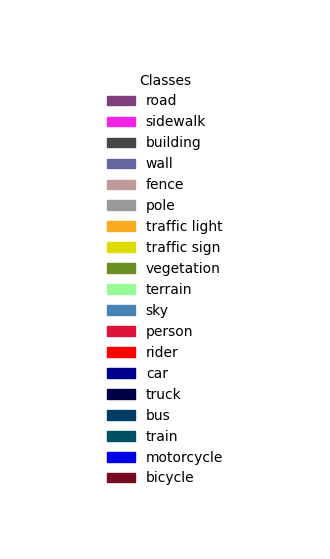

Visualization ready.


In [12]:
def mask_to_color(mask):
    out = np.zeros((*mask.shape, 3), dtype=np.uint8)
    for i in range(len(CITYSCAPES_COLORMAP)):
        out[mask == i] = CITYSCAPES_COLORMAP[i]
    return out

def denorm(t):
    m = np.array([0.485,0.456,0.406])
    s = np.array([0.229,0.224,0.225])
    return np.clip((t.cpu().numpy().transpose(1,2,0)*s+m)*255,0,255).astype(np.uint8)

def save_grid(images, gts, preds, path, epoch=None):
    n = min(len(images), 4)
    fig, axes = plt.subplots(n, 3, figsize=(15, 5*n))
    if n == 1: axes = axes[np.newaxis,:]
    for c, t in enumerate(['Input','Ground Truth','Prediction']):
        axes[0,c].set_title(t, fontsize=13, fontweight='bold')
    for i in range(n):
        axes[i,0].imshow(denorm(images[i]))
        axes[i,1].imshow(mask_to_color(gts[i].numpy()))
        axes[i,2].imshow(mask_to_color(preds[i].numpy()))
        for c in range(3): axes[i,c].axis('off')
    fig.suptitle(f'Epoch {epoch}' if epoch else 'Predictions', fontsize=14)
    plt.tight_layout()
    plt.savefig(path, dpi=90, bbox_inches='tight')
    plt.close()
    display(IPImage(path))

def save_curves(hist, path):
    ep = range(1, len(hist['tl'])+1)
    fig,(a1,a2) = plt.subplots(1,2,figsize=(12,4))
    a1.plot(ep,hist['tl'],label='Train',color='steelblue',lw=2)
    a1.plot(ep,hist['vl'],label='Val',  color='coral',    lw=2)
    a1.set(xlabel='Epoch',ylabel='Loss',title='Loss')
    a1.legend(); a1.grid(alpha=0.3)
    a2.plot(ep,[m*100 for m in hist['vm']],color='mediumseagreen',lw=2)
    a2.set(xlabel='Epoch',ylabel='mIoU (%)',title='Val mIoU')
    a2.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(path,dpi=100,bbox_inches='tight')
    plt.close()
    display(IPImage(path))

# Save legend
fig, ax = plt.subplots(figsize=(4,7)); ax.axis('off')
ax.legend(
    handles=[mpatches.Patch(color=CITYSCAPES_COLORMAP[i]/255., label=n)
             for i,n in enumerate(CITYSCAPES_CLASSES)],
    loc='center', fontsize=10, title='Classes', frameon=False
)
leg_path = os.path.join(OUTPUT_DIR, 'legend.png')
plt.savefig(leg_path, dpi=100, bbox_inches='tight')
plt.close()
display(IPImage(leg_path))
print('Visualization ready.')

In [13]:
class EarlyStopping:
    def __init__(self, patience=15):
        self.patience   = patience
        self.best       = -np.inf
        self.best_epoch = 0
        self.counter    = 0
        self.path       = os.path.join(OUTPUT_DIR, 'best_model.pth')

    def __call__(self, miou, model, epoch):
        if miou > self.best + 0.001:
            self.best       = miou
            self.best_epoch = epoch
            self.counter    = 0
            torch.save(model.state_dict(), self.path)
            print(f'  Best mIoU: {miou*100:.2f}% — saved')
        else:
            self.counter += 1
            print(f'  No improvement {self.counter}/{self.patience} | best={self.best*100:.2f}% @ep{self.best_epoch}')
            if self.counter >= self.patience:
                print('Early stopping triggered.')
                return True
        return False

stopper = EarlyStopping(PATIENCE)
print('Early stopping ready.')

Early stopping ready.


In [14]:
def train_one_epoch(epoch):
    model.train()
    total_loss = 0.0
    n          = 0
    t0         = time.time()
    optimizer.zero_grad()

    for step, (imgs, lbls) in enumerate(train_loader):
        imgs = imgs.to(DEVICE)
        lbls = lbls.to(DEVICE)

        with torch.amp.autocast('cuda', enabled=FP16):
            out  = model(pixel_values=imgs)
            up   = F.interpolate(out.logits, size=lbls.shape[-2:],
                                 mode='bilinear', align_corners=False)
            loss = criterion(up, lbls) / ACCUMULATION_STEPS

        scaler.scale(loss).backward()
        total_loss += loss.item() * ACCUMULATION_STEPS
        n          += 1

        if (step + 1) % ACCUMULATION_STEPS == 0 or (step + 1) == len(train_loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()
            scheduler.step()

    avg = total_loss / max(n, 1)
    lr_ = scheduler.get_last_lr()[0]
    print(f'  [Train] loss={avg:.4f}  lr={lr_:.2e}  time={time.time()-t0:.0f}s')
    return avg


@torch.no_grad()
def validate(epoch, save_viz=False):
    model.eval()
    total_loss = 0.0
    n          = 0
    metrics.reset()
    vi, vg, vp = [], [], []

    for imgs, lbls in val_loader:
        imgs = imgs.to(DEVICE)
        lbls = lbls.to(DEVICE)

        with torch.amp.autocast('cuda', enabled=FP16):
            out = model(pixel_values=imgs)
            up  = F.interpolate(out.logits, size=lbls.shape[-2:],
                                mode='bilinear', align_corners=False)

        total_loss += criterion(up, lbls).item()
        n          += 1
        preds = up.argmax(dim=1)
        metrics.update(preds, lbls)

        if len(vi) < 4:
            vi.extend(imgs.cpu())
            vg.extend(lbls.cpu())
            vp.extend(preds.cpu())

    avg  = total_loss / max(n, 1)
    miou, _ = metrics.compute()
    print(f'  [Val]   loss={avg:.4f}  mIoU={miou*100:.2f}%')

    if save_viz:
        save_grid(vi, vg, vp,
                  os.path.join(OUTPUT_DIR, f'pred_ep{epoch}.png'), epoch)

    return avg, miou


print('Train/validate functions ready.')

Train/validate functions ready.


  Run    : segformer-b2-full-cityscapes
  Model  : SegFormer-B2  device=cuda
  Epochs : 50  freeze=15  warmup=5
  Train  : 2975  Val: 500


--- Epoch 1/50  [decoder-only] ---
  [Train] loss=0.0871  lr=1.00e-05  time=288s
  [Val]   loss=0.2473  mIoU=65.02%

  Epoch 1
  Class                    IoU
  ----------------------------
  road                   96.8%  ███████████████████
  sidewalk               77.4%  ███████████████
  building               87.6%  █████████████████
  wall                   53.3%  ██████████
  fence                  45.6%  █████████
  pole                   38.4%  ███████
  traffic light          46.1%  █████████
  traffic sign           58.3%  ███████████
  vegetation             87.4%  █████████████████
  terrain                59.6%  ███████████
  sky                    90.2%  ██████████████████
  person                 60.1%  ████████████
  rider                  36.1%  ███████
  car                    89.5%  █████████████████
  truck                  69.9%

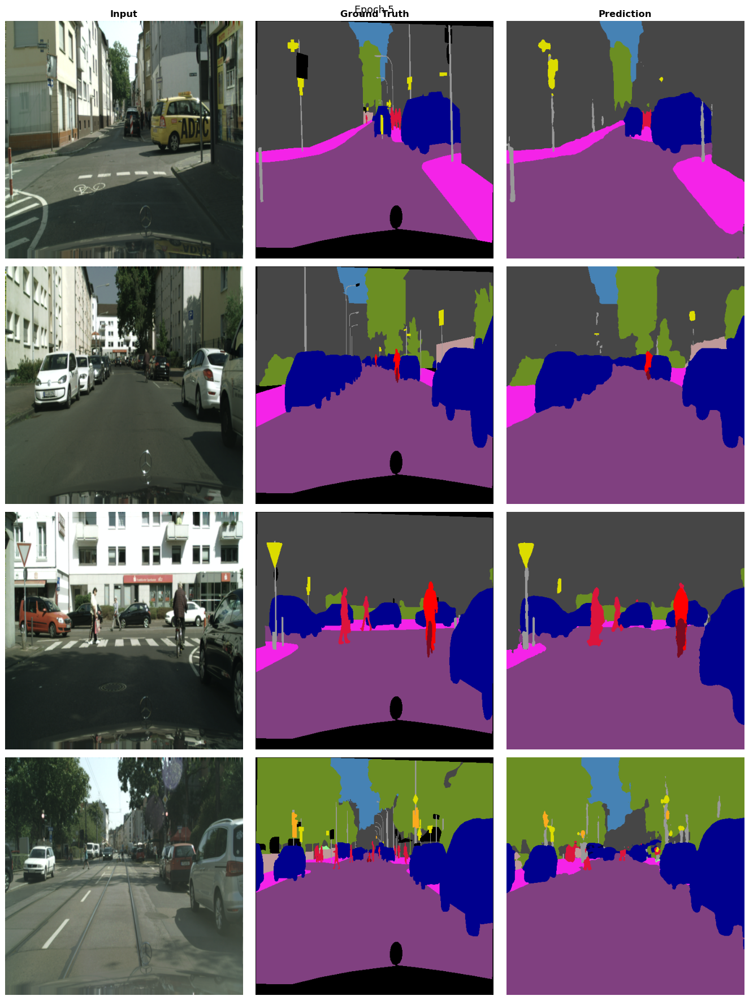

  Best mIoU: 65.86% — saved

--- Epoch 6/50  [decoder-only] ---
  [Train] loss=0.0793  lr=6.01e-05  time=290s
  [Val]   loss=0.2308  mIoU=65.83%
  No improvement 1/15 | best=65.86% @ep5

--- Epoch 7/50  [decoder-only] ---
  [Train] loss=0.0753  lr=7.01e-05  time=290s
  [Val]   loss=0.2286  mIoU=66.05%
  Best mIoU: 66.05% — saved

--- Epoch 8/50  [decoder-only] ---
  [Train] loss=0.0764  lr=8.01e-05  time=291s
  [Val]   loss=0.2289  mIoU=66.08%
  No improvement 1/15 | best=66.05% @ep7

--- Epoch 9/50  [decoder-only] ---
  [Train] loss=0.0774  lr=9.01e-05  time=294s
  [Val]   loss=0.2257  mIoU=66.17%
  Best mIoU: 66.17% — saved

--- Epoch 10/50  [decoder-only] ---
  [Train] loss=0.0769  lr=1.00e-04  time=292s
  [Val]   loss=0.2251  mIoU=66.10%


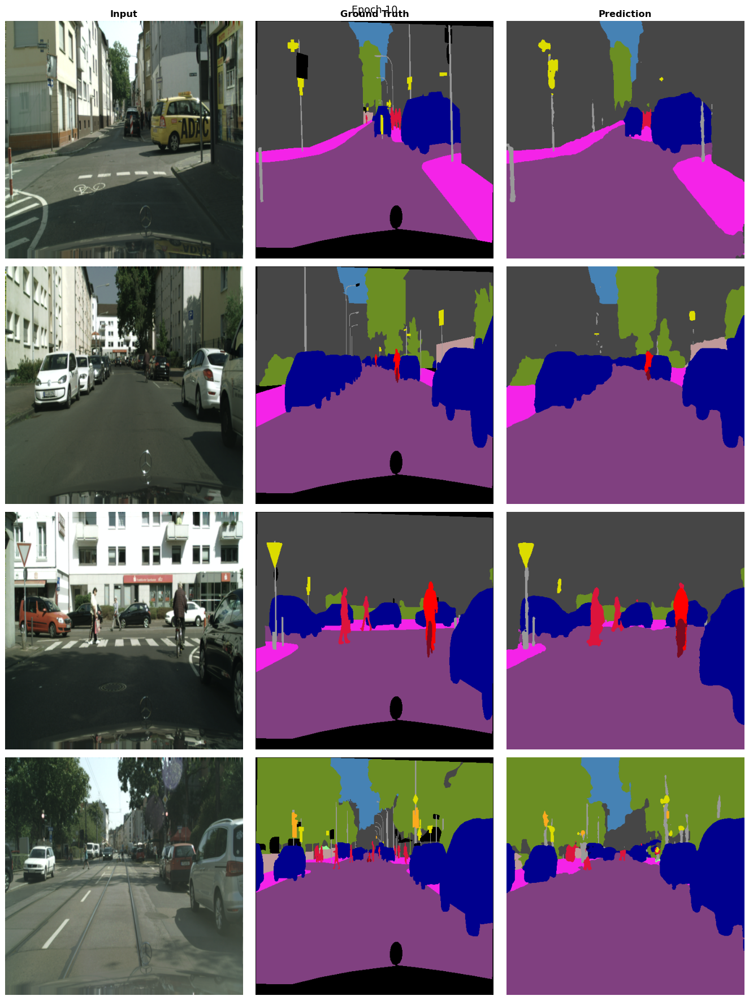


  Epoch 10
  Class                    IoU
  ----------------------------
  road                   97.1%  ███████████████████
  sidewalk               79.0%  ███████████████
  building               88.2%  █████████████████
  wall                   53.2%  ██████████
  fence                  46.5%  █████████
  pole                   40.4%  ████████
  traffic light          47.6%  █████████
  traffic sign           60.8%  ████████████
  vegetation             88.3%  █████████████████
  terrain                60.3%  ████████████
  sky                    91.0%  ██████████████████
  person                 61.7%  ████████████
  rider                  37.1%  ███████
  car                    90.5%  ██████████████████
  truck                  70.8%  ██████████████
  bus                    77.4%  ███████████████
  train                  67.5%  █████████████
  motorcycle             36.8%  ███████
  bicycle                61.5%  ████████████
  ----------------------------
  mIoU                  

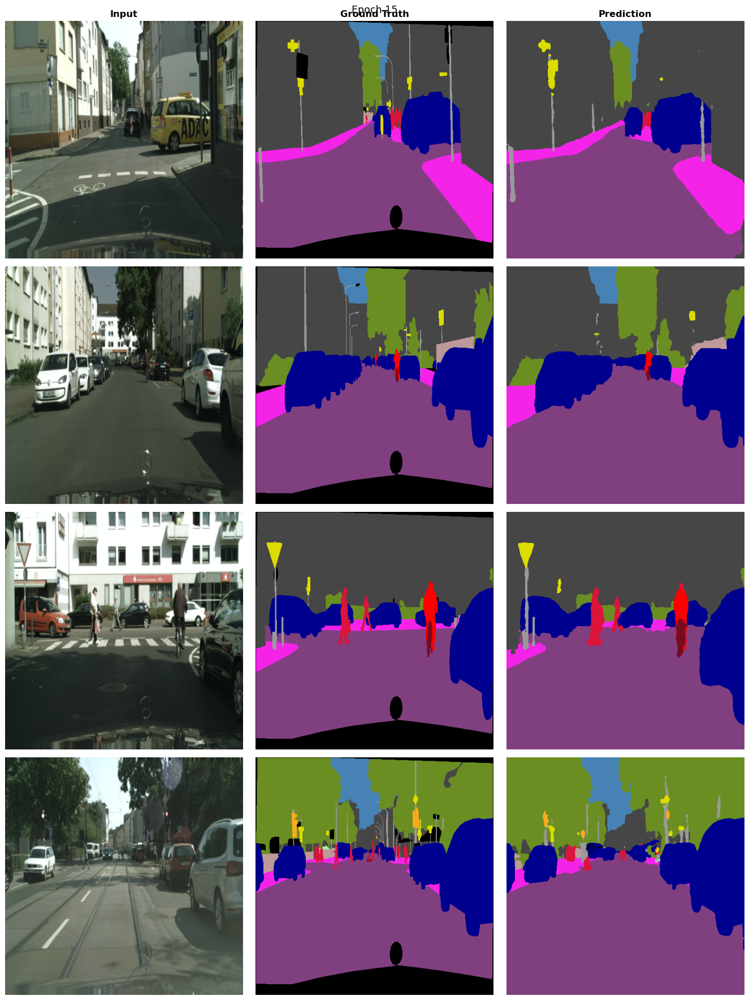

  No improvement 6/15 | best=66.17% @ep9

  PHASE 2: Unfreeze encoder
  Trainable : 27,361,235 / 27,361,235

--- Epoch 16/50  [full] ---
  [Train] loss=0.0735  lr=1.00e-06  time=310s
  [Val]   loss=0.2252  mIoU=66.19%
  No improvement 7/15 | best=66.17% @ep9

--- Epoch 17/50  [full] ---
  [Train] loss=0.0728  lr=2.00e-06  time=307s
  [Val]   loss=0.2227  mIoU=66.31%
  Best mIoU: 66.31% — saved

--- Epoch 18/50  [full] ---
  [Train] loss=0.0732  lr=3.00e-06  time=306s
  [Val]   loss=0.2253  mIoU=66.08%
  No improvement 1/15 | best=66.31% @ep17

--- Epoch 19/50  [full] ---
  [Train] loss=0.0708  lr=4.01e-06  time=305s
  [Val]   loss=0.2243  mIoU=66.20%
  No improvement 2/15 | best=66.31% @ep17

--- Epoch 20/50  [full] ---
  [Train] loss=0.0705  lr=5.01e-06  time=304s
  [Val]   loss=0.2270  mIoU=66.21%


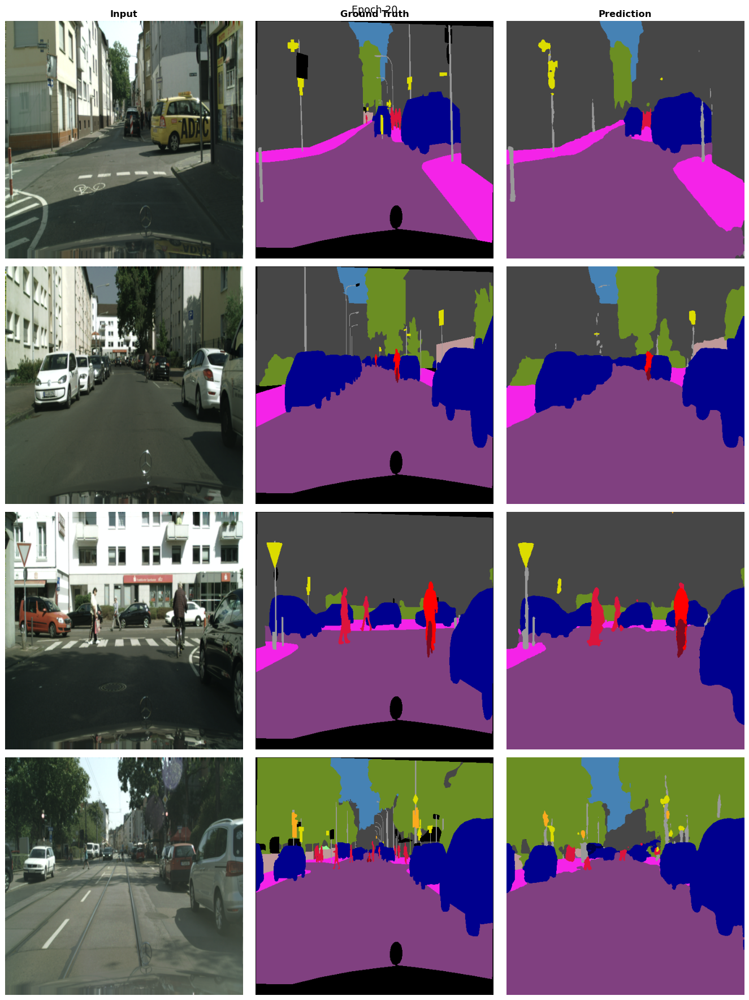


  Epoch 20
  Class                    IoU
  ----------------------------
  road                   97.1%  ███████████████████
  sidewalk               78.6%  ███████████████
  building               88.2%  █████████████████
  wall                   54.5%  ██████████
  fence                  48.0%  █████████
  pole                   41.0%  ████████
  traffic light          48.1%  █████████
  traffic sign           61.6%  ████████████
  vegetation             88.2%  █████████████████
  terrain                60.0%  ███████████
  sky                    91.0%  ██████████████████
  person                 61.8%  ████████████
  rider                  37.8%  ███████
  car                    90.6%  ██████████████████
  truck                  68.3%  █████████████
  bus                    76.3%  ███████████████
  train                  65.9%  █████████████
  motorcycle             39.0%  ███████
  bicycle                62.0%  ████████████
  ----------------------------
  mIoU                   6

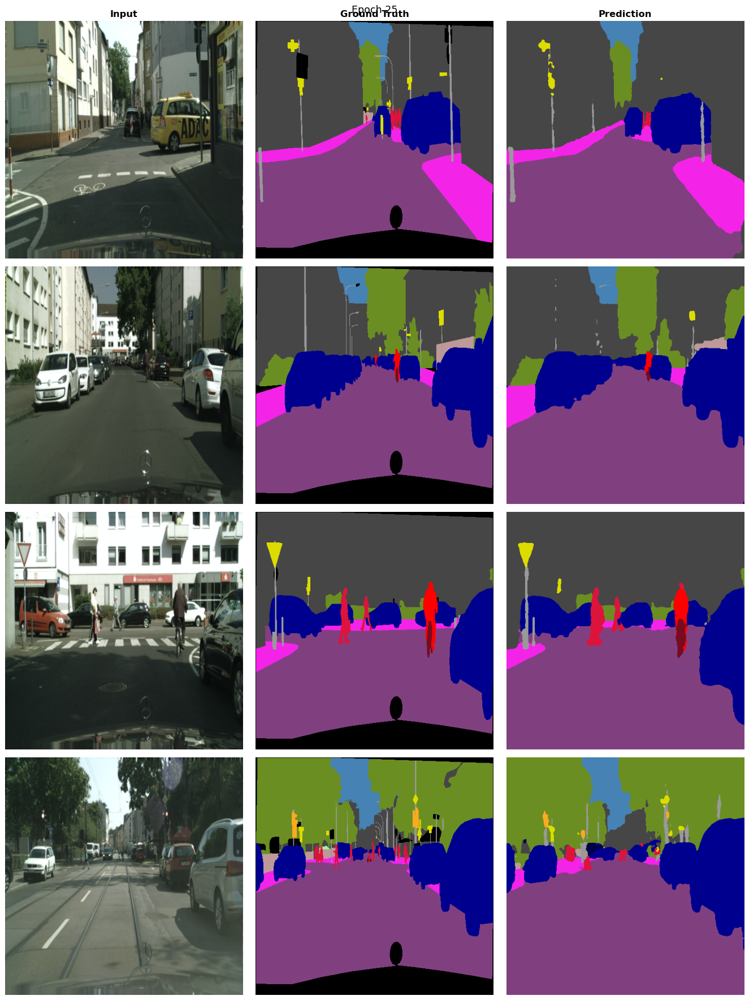

  No improvement 8/15 | best=66.31% @ep17

--- Epoch 26/50  [full] ---
  [Train] loss=0.0697  lr=9.85e-06  time=318s
  [Val]   loss=0.2399  mIoU=65.40%
  No improvement 9/15 | best=66.31% @ep17

--- Epoch 27/50  [full] ---
  [Train] loss=0.0700  lr=9.70e-06  time=316s
  [Val]   loss=0.2349  mIoU=65.74%
  No improvement 10/15 | best=66.31% @ep17

--- Epoch 28/50  [full] ---
  [Train] loss=0.0695  lr=9.55e-06  time=317s
  [Val]   loss=0.2385  mIoU=65.64%
  No improvement 11/15 | best=66.31% @ep17

--- Epoch 29/50  [full] ---
  [Train] loss=0.0685  lr=9.40e-06  time=317s
  [Val]   loss=0.2390  mIoU=65.21%
  No improvement 12/15 | best=66.31% @ep17

--- Epoch 30/50  [full] ---
  [Train] loss=0.0692  lr=9.24e-06  time=327s
  [Val]   loss=0.2277  mIoU=65.93%


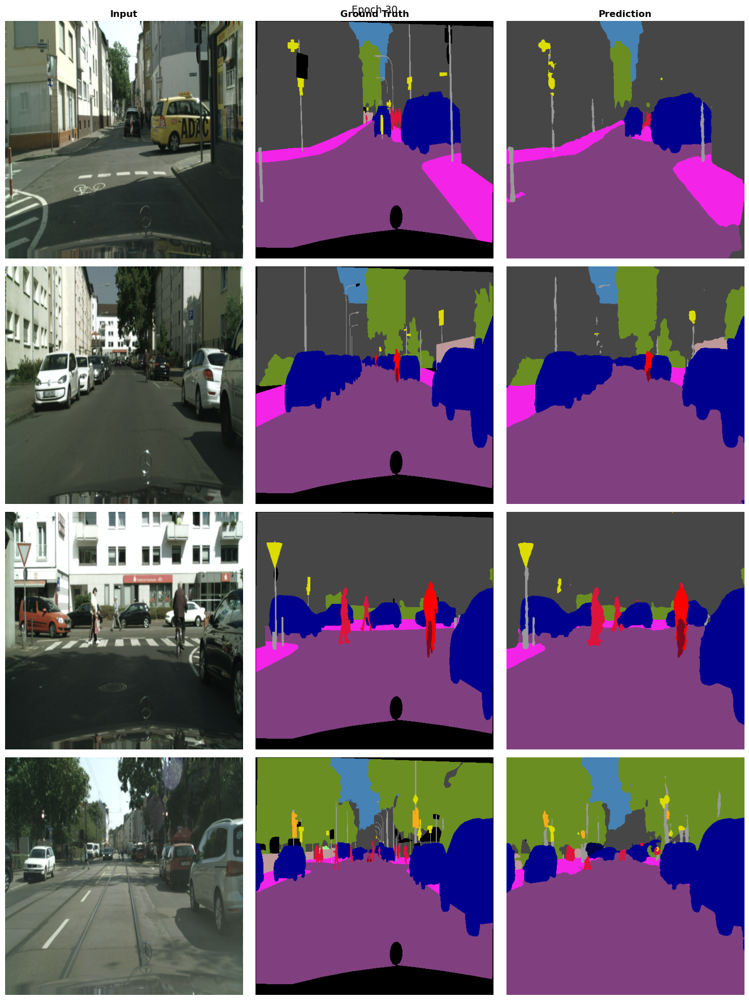


  Epoch 30
  Class                    IoU
  ----------------------------
  road                   97.1%  ███████████████████
  sidewalk               78.4%  ███████████████
  building               88.3%  █████████████████
  wall                   53.2%  ██████████
  fence                  46.8%  █████████
  pole                   40.7%  ████████
  traffic light          49.0%  █████████
  traffic sign           61.8%  ████████████
  vegetation             88.4%  █████████████████
  terrain                60.2%  ████████████
  sky                    90.9%  ██████████████████
  person                 61.9%  ████████████
  rider                  37.2%  ███████
  car                    90.8%  ██████████████████
  truck                  65.8%  █████████████
  bus                    75.5%  ███████████████
  train                  66.6%  █████████████
  motorcycle             38.4%  ███████
  bicycle                61.6%  ████████████
  ----------------------------
  mIoU                   

In [15]:
print('='*55)
print(f'  Run    : {RUN_NAME}')
print(f'  Model  : SegFormer-{MODEL_VARIANT.upper()}  device={DEVICE}')
print(f'  Epochs : {EPOCHS}  freeze={FREEZE_EPOCHS}  warmup={WARMUP_EPOCHS}')
print(f'  Train  : {len(train_ds)}  Val: {len(val_ds)}')
print('='*55+'\n')

hist  = {'tl':[], 'vl':[], 'vm':[]}
PHASE = 'decoder-only' if IS_FROZEN else 'full'

for epoch in range(1, EPOCHS+1):

    # Phase 2 transition
    if epoch == FREEZE_EPOCHS + 1 and FREEZE_EPOCHS > 0:
        print('\n'+'='*55)
        print('  PHASE 2: Unfreeze encoder')
        print('='*55)
        unfreeze_all(model)
        PHASE     = 'full'
        optimizer = build_optimizer(frozen=False)
        scheduler = build_scheduler(optimizer, EPOCHS - epoch + 1)
        scaler    = torch.amp.GradScaler('cuda', enabled=FP16)
        count_params(model)

    print(f'\n--- Epoch {epoch}/{EPOCHS}  [{PHASE}] ---')

    tl = train_one_epoch(epoch)
    do_viz = (epoch % SAVE_VIZ_EVERY == 0) or epoch == EPOCHS
    vl, vm = validate(epoch, save_viz=do_viz)

    if epoch % 10 == 0 or epoch == 1:
        metrics.print_table(epoch)

    hist['tl'].append(tl)
    hist['vl'].append(vl)
    hist['vm'].append(vm)

    if stopper(vm, model, epoch):
        break

print('\n'+'='*55)
print('TRAINING COMPLETE')
best_ep = int(np.argmax(hist['vm'])) + 1
print(f'  Best epoch : {best_ep}')
print(f'  Best mIoU  : {max(hist["vm"])*100:.2f}%')
print(f'  Checkpoint : {stopper.path}')
print('='*55)